In [27]:
from mqt.qudits.quantum_circuit import QuantumCircuit, QuantumRegister
from mqt.qudits.quantum_circuit.components import ClassicRegister
from mqt.qudits.quantum_circuit.gate import ControlData
from mqt.qudits.visualisation import draw_qudit_local
from math import pi
import numpy as np
from random import random


In [15]:
def rename(counts):
    new_counts = {}
    trans = {"00": "00","10": "01", "01": "10","11": "11"}
    for key in counts:
        new_counts[trans[key]] = counts[key]
    return new_counts

In [16]:
def R01(theta):
    return np.array([
        [np.cos(theta), -np.sin(theta), 0],
        [np.sin(theta),  np.cos(theta), 0],
        [0,              0,             1]
    ], dtype=complex)

In [17]:
def R12(theta):
    return np.array([
        [1, 0, 0],
        [0, np.cos(theta), -np.sin(theta)],
        [0, np.sin(theta), np.cos(theta)]
    ], dtype=complex)

In [ ]:
def run_circuit(alpha, beta, theta0, theta1, chi, runs=10000):
    circ = QuantumCircuit()
    qreg = QuantumRegister("qubit", 1, [2])
    areg = QuantumRegister("ancilla", 1, [3])
    creg = ClassicRegister("c",1)
    circ.append(qreg)
    circ.append(areg)
    circ.append_classic(creg)
    U = np.array([
        [alpha, -np.conj(beta)],
        [beta,   np.conj(alpha)]
    ], dtype=complex)
    circ.cu_one(0, U)
    circ.cu_one(1, R01(theta0), ControlData([0], [0]))
    circ.cu_one(1, R01(theta1), ControlData([0], [1]))
    circ.h(0)
    circ.cu_one(1, R12(chi), ControlData([0], [0]))
    circ.cu_one(1, R12(pi/2-chi), ControlData([0], [1]))
    circ.h(0)
    circ.measure(1, areg)
    display(circ.draw('mpl'))
    job = sim.run(circ, shots=runs)
    out = job.result().get_counts()
    return out



In [35]:
circ = QuantumCircuit()
qreg = QuantumRegister("qubit", 1, [2])
areg = QuantumRegister("ancilla", 1, [3])
creg = ClassicRegister("c",1)
print([m for m in dir(circ) if not m.startswith('_')])

['append', 'append_classic', 'cl_inverse_sitemap', 'classic_registers', 'classic_site_map', 'compileO0', 'compileO1', 'copy', 'csum', 'cu_multi', 'cu_one', 'cu_two', 'cx', 'dimensions', 'from_qasm', 'gate_set', 'gellmann', 'get_qasm_set', 'h', 'instructions', 'inverse_sitemap', 'load_from_file', 'ls', 'mappings', 'ms', 'noisex', 'noisey', 'noisez', 'num_cl', 'num_qudits', 'number_gates', 'path_save', 'pm', 'qasm_to_gate_set_dict', 'quantum_registers', 'r', 'randu', 'replace_gate', 'reset', 'rh', 'rz', 's', 'save_to_file', 'set_initial_state', 'set_instructions', 'set_mapping', 'simulate', 'sitemap', 'to_qasm', 'virtrz', 'x', 'z']


In [33]:
statistics = run_circuit(1/np.sqrt(2),-1/np.sqrt(2),pi/4,pi/2,pi/3)


AttributeError: 'QuantumCircuit' object has no attribute 'measure'

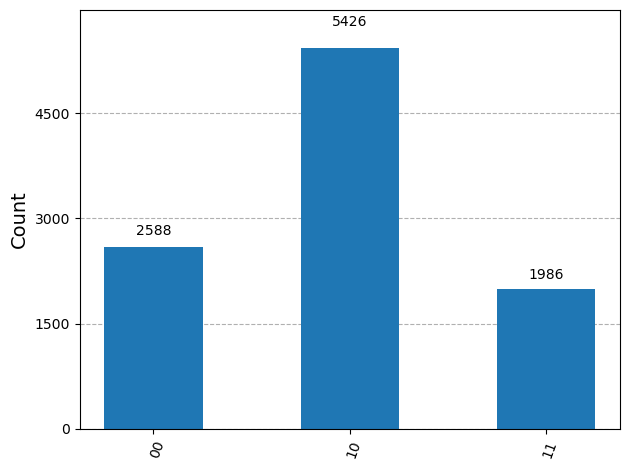

In [89]:
plot_histogram(statistics)